Hei, her er starten på prosjekt 2

(100, 1) (100,)


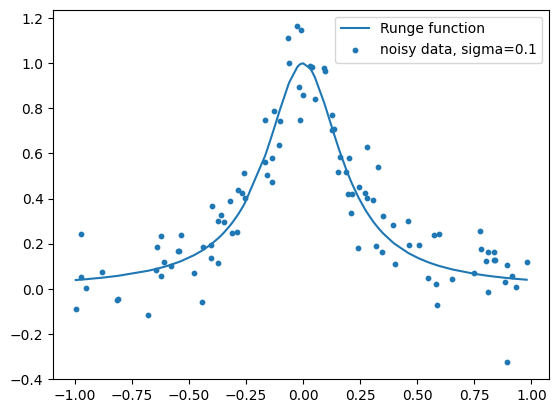

In [9]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp  
from sklearn.model_selection import train_test_split

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)  # Standardize the input features
y_scaled = (y - y.mean()) / y.std()  # Standardize the target variable

Yrunge = runge(X.flatten())
Yrunge_scaled = (Yrunge - Yrunge.mean()) / Yrunge.std()  # Standardize the Runge function values

In [2]:
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)

def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)

def leaky_ReLU(z):
    return jnp.where(z > 0, z, 0.01*z)

def leaky_ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.01)

def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))

def sigmoid_der(z):
    return jnp.exp(-z)/((1+jnp.exp(-z))**2)

def mse_der(predict, target):
    return 2*(predict - target)/predict.size

def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = a @ W + b
        a = activation_func(z)
    return a

def feed_forward_saver(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a@W + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a

def backpropagation(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = mse_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = dC_dz@W.T

        dC_dz = dC_da*activation_der(z)
        dC_dW = layer_input.T @ dC_dz
        dC_db = np.sum(dC_dz, axis = 0)

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

def step_length(t, t0, t1):
    """The schedule of Eq. (4.40)."""
    return t0/(t+t1)

In [3]:
def train_sgd_adam(
        Xtrain,
        Ytrain,
        layers,
        activation_funcs,
        activation_ders,
        epochs,
        batch_size,
        gamma,
        beta1=0.9,
        beta2=0.999,
        use_decaying_step_length=False,
        t0=1.0,
        t1=100.0,
        cost_der=mse_der
):

    """LLM assisted (Copilot)"""
    momentums = [(np.zeros_like(W), np.zeros_like(b)) for (W, b) in layers]
    rs = [(np.zeros_like(W), np.zeros_like(b)) for (W, b) in layers]
    n_samples = Xtrain.shape[0]

    for epoch in range(epochs):
        # Shuffle the data at the beginning of each epoch
        indices = np.arange(n_samples)
        np.random.shuffle(indices)
        Xtrain = Xtrain[indices]
        Ytrain = Ytrain[indices]

        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            Xbatch = Xtrain[start:end]
            Ybatch = Ytrain[start:end]

            layer_grads = backpropagation(Xbatch, layers, activation_funcs, Ybatch, activation_ders, cost_der = cost_der)

            for i in range(len(layers)):
                dC_dW, dC_db = layer_grads[i]
                m_W, m_b = momentums[i]
                r_W, r_b = rs[i]

                # Update biased first moment estimate
                m_W = beta1 * m_W + (1 - beta1) * dC_dW
                m_b = beta1 * m_b + (1 - beta1) * dC_db

                # Update biased second raw moment estimate
                r_W = beta2 * r_W + (1 - beta2) * (dC_dW ** 2)
                r_b = beta2 * r_b + (1 - beta2) * (dC_db ** 2)

                # Compute bias-corrected first moment estimate
                m_W_hat = m_W / (1 - beta1 ** (epoch + 1))
                m_b_hat = m_b / (1 - beta1 ** (epoch + 1))

                # Compute bias-corrected second raw moment estimate
                r_W_hat = r_W / (1 - beta2 ** (epoch + 1))
                r_b_hat = r_b / (1 - beta2 ** (epoch + 1))

                # Update parameters
                gamma_t = step_length(epoch + 1, t0, t1) if use_decaying_step_length else gamma
                layers[i] = (
                    layers[i][0] - gamma_t * m_W_hat / (np.sqrt(r_W_hat) + 1e-8),
                    layers[i][1] - gamma_t * m_b_hat / (np.sqrt(r_b_hat) + 1e-8)
                )

                # Store updated momentums and second moments
                momentums[i] = (m_W, m_b)
                rs[i] = (r_W, r_b)
    return layers

In [4]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50, 1]
layers_one_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_one_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_one_hidden_layer,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


In [5]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50,50, 1]
layers_two_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_two_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_two_hidden_layer,
    activation_funcs = [sigmoid, sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


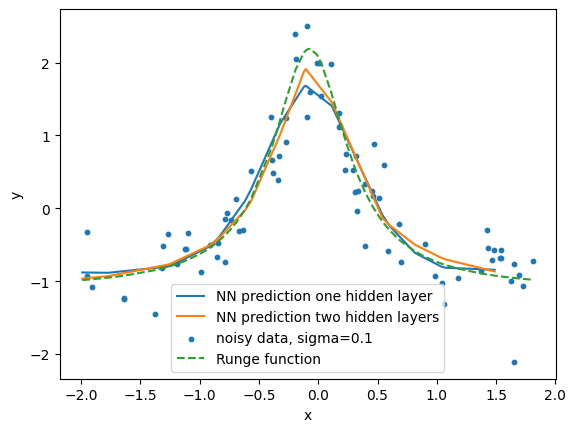

In [6]:
y_pred_one_hidden_layers = feed_forward(Xtest, layers_one_hidden_layer, [sigmoid, lambda z: z])
y_pred_two_hidden_layers = feed_forward(Xtest, layers_two_hidden_layer, [sigmoid, sigmoid, lambda z: z])
sort_idx = np.argsort(Xtest.flatten()) #<- Chatgpt la til fix

plt.plot(Xtest[sort_idx], y_pred_one_hidden_layers[sort_idx], label="NN prediction one hidden layer")
plt.plot(Xtest[sort_idx], y_pred_two_hidden_layers[sort_idx], label="NN prediction two hidden layers")

plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.plot(X_scaled, Yrunge_scaled, label="Runge function", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [7]:
MSE_one_hidden = np.mean((y_pred_one_hidden_layers.flatten() - ytest)**2)
print(f"MSE for one hidden layer: {MSE_one_hidden}")

MSE_two_hidden = np.mean((y_pred_two_hidden_layers.flatten() - ytest)**2)
print(f"MSE for two hidden layers: {MSE_two_hidden}")

MSE for one hidden layer: 0.1553586721420288
MSE for two hidden layers: 0.1287248432636261


In [ ]:
def mse(predict, target):
    return jnp.mean((predict - target) ** 2)

def cost(layers, input, activation_funcs, target):
    predict = feed_forward(input, layers, activation_funcs)
    return mse(predict, target)

cost_grad = jax.grad(cost, argnums=0)

layers = create_layers(1,[50, 1])

layer_grads = backpropagation(Xtrain, layers, [sigmoid, lambda z: z], target = ytrain.reshape(-1,1), activation_ders = [sigmoid_der, lambda z: np.ones_like(z)])

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, Xtrain, [sigmoid, lambda z: z], ytrain.reshape(-1, 1))
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

In [8]:
cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, x, [sigmoid, ReLU], target)
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

NameError: name 'jax' is not defined

In [ ]:
functions = [ReLU, leaky_ReLU, sigmoid]
number_of_nodes = np.arange(2,10,2)  # Example range of nodes
number_of_hidden_layers = np.arange(1, 4)  # Example range of hidden layers

for function in functions:
    for n_layers in number


SyntaxError: expected ':' (805249612.py, line 6)